# Sample non-dimensional planetary-geostrophic problem

This notebook specifies a PG problem, solves for surface pressure, samples the full 3D solution, writes VTK files, and plots a horizontal slice.

In [1]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "..", "PlanetaryGeostrophy"))
using PlanetaryGeostrophy

  Activating project at `~/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy`


In [2]:
Lx, Ly = 2.0, 1.5
H0 = 1.0
boundary = rectangle_boundary(Lx, Ly)
parameters = PGParameters(0.02, 0.20; viscosity=1.0, diffusivity=1.0)

problem = PGProblem(
    parameters=parameters,
    depth=(x, y) -> H0,
    depth_x=(x, y) -> 0.0,
    depth_y=(x, y) -> 0.0,
    coriolis=(x, y) -> 1.0 + 0.15y,
    coriolis_x=(x, y) -> 0.0,
    coriolis_y=(x, y) -> 0.15,
    wind_stress=(x, y) -> 1e-3 * cos(pi * y / Ly) + 0im,
    restoring_buoyancy=(x, y, z) -> 1e-2z + 2e-3 * sin(pi * x / Lx),
    surface_buoyancy=(x, y) -> 2e-3 * cos(pi * x / Lx) * cos(pi * y / Ly),
    boundary=boundary,
)

PGProblem{PGParameters{Float64}, var"#31#32", var"#37#38", var"#39#40", var"#41#42", var"#43#44", var"#45#46", var"#47#48", var"#33#34", var"#35#36", Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#78#79"{Vector{Tuple{Float64, Float64}}}}(PGParameters{Float64}(0.02, 0.2, 1.0, 1.0), var"#31#32"(), var"#37#38"(), var"#39#40"(), var"#41#42"(), var"#43#44"(), var"#45#46"(), var"#47#48"(), var"#33#34"(), var"#35#36"(), [(-1.0, -0.75), (1.0, -0.75), (1.0, 0.75), (-1.0, 0.75)], PlanetaryGeostrophy.var"#78#79"{Vector{Tuple{Float64, Float64}}}([(-1.0, -0.75), (1.0, -0.75), (1.0, 0.75), (-1.0, 0.75)]), 1.0e-5)

In [3]:
solution = solve_pg(
    problem;
    mesh_file=joinpath(@__DIR__, "sample_pg_pressure.msh"),
    mesh_resolution=0.20,
    overwrite_mesh=true,
)

┌ Info: PG solve started
│   Ek = 0.02
│   Γ = 0.2
│   viscosity = 1.0
│   diffusivity = 1.0
│   pressure_order = 2
│   mesh_resolution = 0.2
│   mesh_file = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:195
┌ Info: Starting generating surface mesh
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15


Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Line)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Line)
Info    : Done meshing 1D (Wall 0.000158833s, CPU 0.000124s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00191796s, CPU 0.001884s)
Info    : 117 nodes 236 elements
Info    : Writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh'...
Info    : Done writing '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_pressure.msh'
Info    : Reading '/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/Plan

┌ Info: Completed generating surface mesh
│   seconds = 0.044
│   allocated_mib = 3.54
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Starting loading analytical Green-function kernels
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: Completed loading analytical Green-function kernels
│   seconds = 0.0
│   allocated_mib = 0.0
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Surface-pres

PGSolution{PGProblem{PGParameters{Float64}, var"#31#32", var"#37#38", var"#39#40", var"#41#42", var"#43#44", var"#45#46", var"#47#48", var"#33#34", var"#35#36", Vector{Tuple{Float64, Float64}}, PlanetaryGeostrophy.var"#78#79"{Vector{Tuple{Float64, Float64}}}}, PlanetaryGeostrophy.VelocityFieldPrototype.SymbolicKernels{PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##0#load_symbolic_kernels##1", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##2#load_symbolic_kernels##3", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##4#load_symbolic_kernels##5", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##6#load_symbolic_kernels##7", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##8#load_symbolic_kernels##9", PlanetaryGeostrophy.VelocityFieldPrototype.var"#load_symbolic_kernels##10#load_symbolic_kernels##11"}, @NamedTuple{model::Gridap.Geometry.UnstructuredDiscreteModel{2, 2, Float64, G

In [4]:
x = range(-0.99Lx / 2, 0.99Lx / 2; length=64)
y = range(-0.99Ly / 2, 0.99Ly / 2; length=64)
z = range(-H0, 0.0; length=64)
fields = sample_solution(solution, x, y, z)

┌ Info: Solution sampling started
│   Nx = 64
│   Ny = 64
│   Nz = 64
│   grid_points = 262144
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:544
┌ Info: Starting sampling surface pressure and bathymetry
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: Completed sampling surface pressure and bathymetry
│   seconds = 0.504
│   allocated_mib = 329.83
│   gc_seconds = 0.029
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:18
┌ Info: Starting sampling 3

PGFields{Vector{Float64}, Vector{Float64}, Vector{Float64}, @NamedTuple{surface_fields::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, horizontal_velocity_and_buoyancy::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, vertical_velocity::@NamedTuple{seconds::Float64, allocated_mib::Float64, gc_seconds::Float64}, total_seconds::Float64, wet_points::Int64, wet_points_per_second::Float64}}([-0.99, -0.9585714285714285, -0.9271428571428572, -0.8957142857142857, -0.8642857142857143, -0.8328571428571429, -0.8014285714285714, -0.77, -0.7385714285714285, -0.7071428571428572  …  0.7071428571428572, 0.7385714285714285, 0.77, 0.8014285714285714, 0.8328571428571429, 0.8642857142857143, 0.8957142857142857, 0.9271428571428572, 0.9585714285714285, 0.99], [-0.7424999999999999, -0.7189285714285714, -0.6953571428571428, -0.6717857142857142, -0.6482142857142856, -0.624642857142857, -0.6010714285714285, -0.5774999999999999, -0.5539285714285714, -0.5303

┌ Info: Writing sampled PG solution
│   prefix = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:774
┌ Info: Starting writing 3D VTK fields
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: Completed writing 3D VTK fields
│   seconds = 0.531
│   allocated_mib = 50.47
│   gc_seconds = 0.012
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeost

(volume = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_3D_solution.vtr", surface = "/Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_surface_solution.vtr", timings = (volume = (seconds = 0.531005625, allocated_mib = 50.474090576171875, gc_seconds = 0.011606459), surface = (seconds = 0.135580458, allocated_mib = 10.19317626953125, gc_seconds = 0.0), total_seconds = 0.6680760383605957))

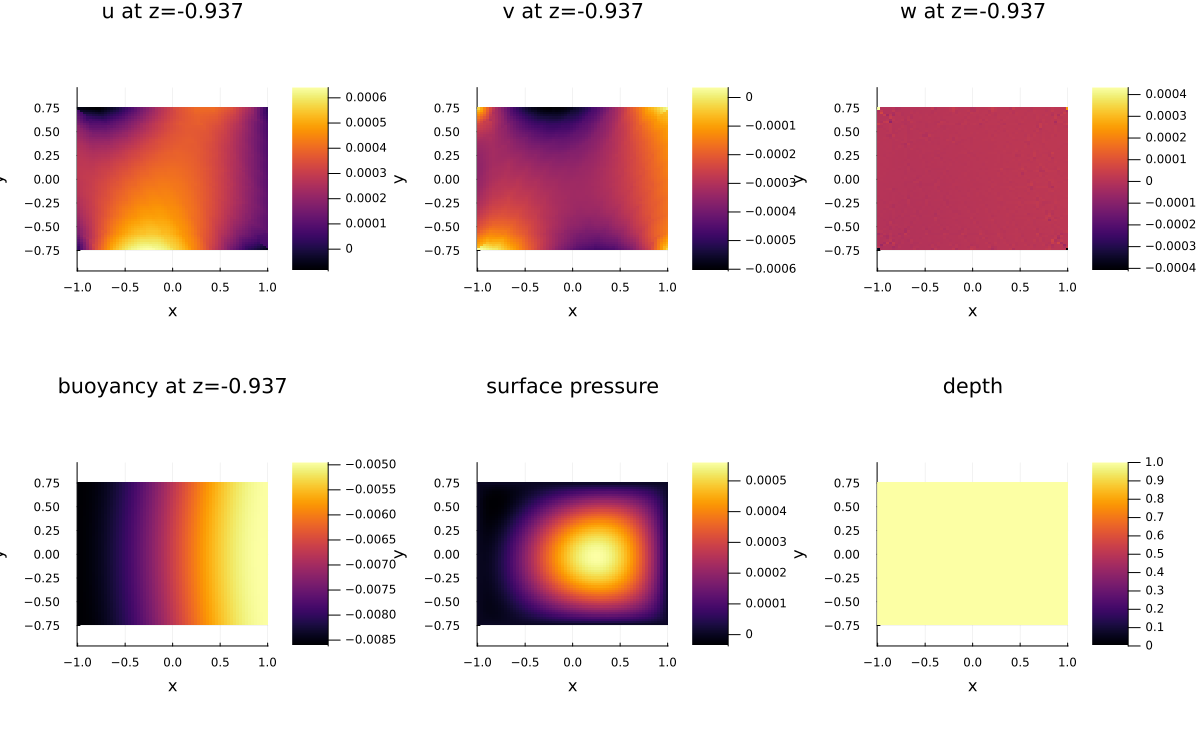

In [5]:
files = write_solution(fields, joinpath(@__DIR__, "sample_pg"))
figure = plot_solution(
    fields;
    z_index=5,
    output=joinpath(@__DIR__, "sample_pg_solution.png"),
)
display(files)
display(figure)

In [6]:
# The direct analytical diagnostic quadratures are more expensive than field sampling.
diagnostic_stride = 4
diagnostic_x = x[1:diagnostic_stride:end]
diagnostic_y = y[1:diagnostic_stride:end]
diagnostics = compute_diagnostics(solution, diagnostic_x, diagnostic_y)
display(performance_summary(diagnostics))

┌ Info: PG diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   horizontal_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:619
┌ Info: Transport streamfunction solve started
│   finite_element_order = 2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:241
┌ Info: Starting constructing streamfunction finite-element spaces
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/SurfacePressureTools.jl:12
┌ Info: Completed constructing streamfunction finite-element spaces
│   seconds = 0

(streamfunction = (finite_element_setup = (seconds = 0.971675416, allocated_mib = 497.3514404296875, gc_seconds = 0.0), current_projection = (seconds = 29.200225625, allocated_mib = 44937.31700134277, gc_seconds = 1.659729105), operator_assembly = (seconds = 2.775801166, allocated_mib = 362.39320373535156, gc_seconds = 0.013150792), linear_solve = (seconds = 0.000511333, allocated_mib = 0.74066162109375, gc_seconds = 0.0), total_seconds = 33.01309514045715), sampling = (seconds = 5.485870792, allocated_mib = 8797.444549560547, gc_seconds = 0.309428252), total_seconds = 38.8197078704834, wet_points = 256, points_per_second = 46.66533531437209, transport_projection_relative_l2 = 0.9558390911346393)

┌ Info: Plotting bottom stress
│   stride = 1
│   arrow_scale = 0.35
│   arrowhead_size = 0.08
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_bottom_stress.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:956
┌ Info: Starting rendering bottom-stress plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: Completed rendering bottom-stress plot
│   seconds = 0.007
│   allocated_mib = 1.24
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-Johns

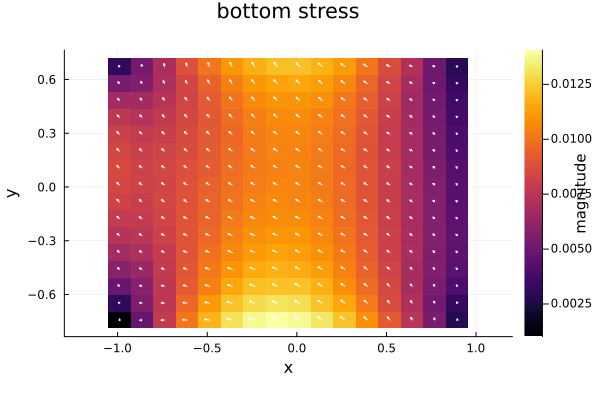

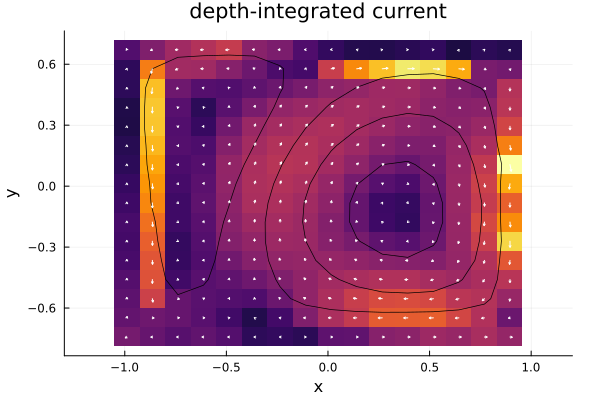

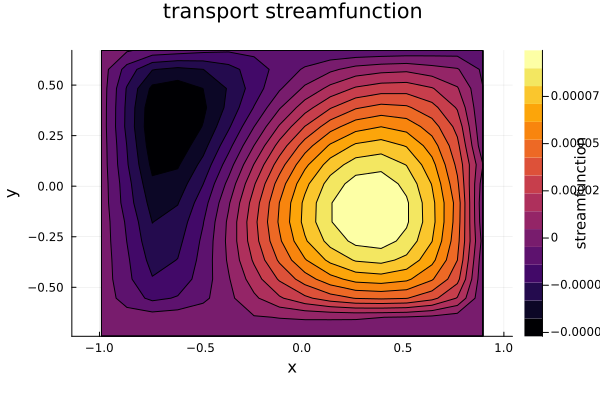

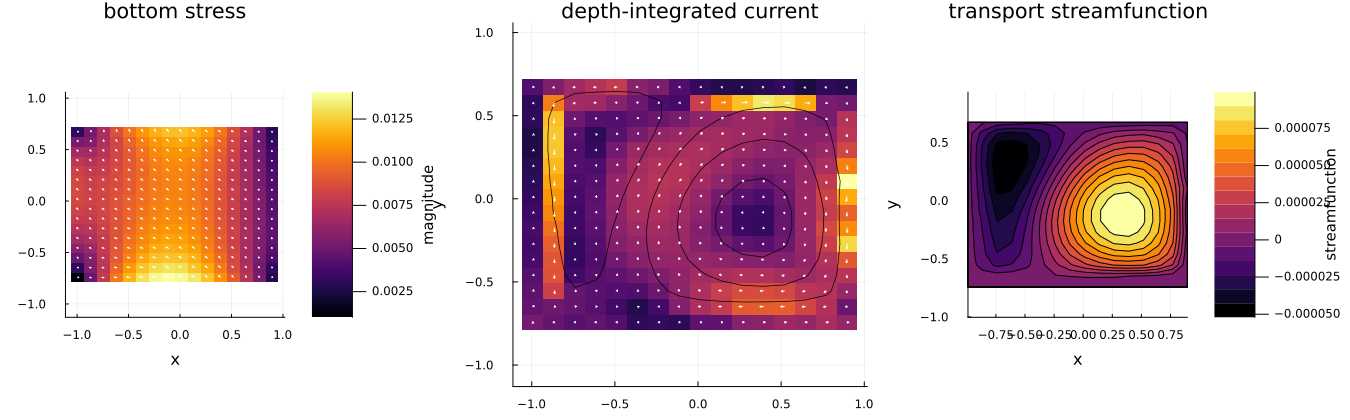

In [7]:
bottom_stress_figure = plot_bottom_stress(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_bottom_stress.png"),
)
transport_figure = plot_depth_integrated_current(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_transport.png"),
)
streamfunction_figure = plot_streamfunction(
    diagnostics;
    output=joinpath(@__DIR__, "sample_pg_streamfunction.png"),
)
diagnostic_figure = plot_diagnostics(
    diagnostics;
    arrow_scale=0.35,
    output=joinpath(@__DIR__, "sample_pg_diagnostics.png"),
)
display(bottom_stress_figure)
display(transport_figure)
display(streamfunction_figure)
display(diagnostic_figure)

## Depth-integrated momentum balance

Compute the terms corresponding to equations (32)--(33), together with bottom pressure $p_b$ and baroclinic potential energy $\chi$. The API consistently uses conventional oceanographic buoyancy, $\partial_z p=b$, with $p=p_s-\int_z^0 b\,dz$.

In [8]:
dim = compute_dim_diagnostics(solution, diagnostics)
display(performance_summary(dim))

┌ Info: DIM diagnostic calculation started
│   Nx = 16
│   Ny = 16
│   wet_points = 256
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:708
┌ Info: Starting sampling depth-integrated momentum terms
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: DIM diagnostic sampling progress
│   rows_completed = 1
│   rows_total = 16
│   percent = 6.2
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:733
┌ Info: DIM diagnostic sampling progress
│   rows_completed 

(sampling = (seconds = 5.892112959, allocated_mib = 9002.653350830078, gc_seconds = 0.34630342), total_seconds = 5.8936378955841064, x_relative_l2_residual = 8.893356619503479e-11, y_relative_l2_residual = 1.2156246314775576e-10)

┌ Info: Plotting depth-integrated momentum balance
│   component = both
│   output = /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/Analytical Model/sample_pg_dim_balance.png
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:1127
┌ Info: Starting rendering DIM balance plot
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/Manuscripts/In prep/Haine_etal/WorkingResearch/PlanetaryGeostrophyAnalyticalModel/PlanetaryGeostrophy/src/PlanetaryGeostrophy.jl:15
┌ Info: Completed rendering DIM balance plot
│   seconds = 0.142
│   allocated_mib = 18.12
│   gc_seconds = 0.0
└ @ PlanetaryGeostrophy /Users/twnh/Library/CloudStorage/OneDrive-JohnsHopkins/Documents/Articles/

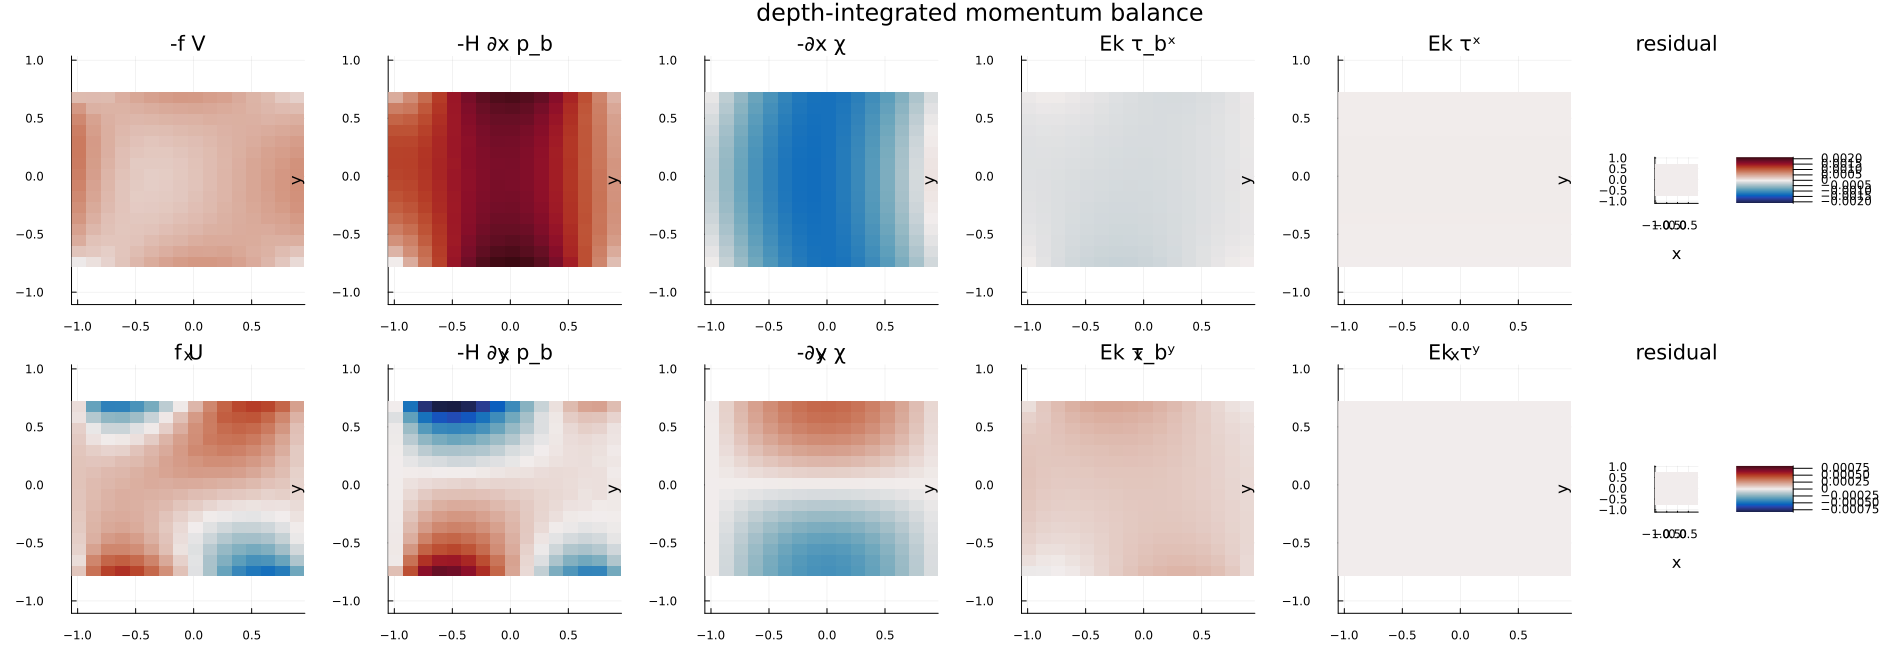

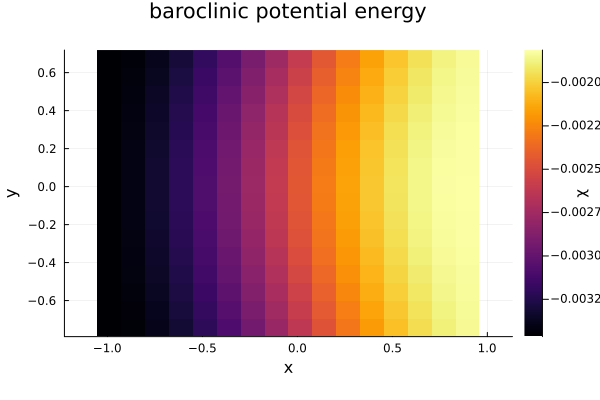

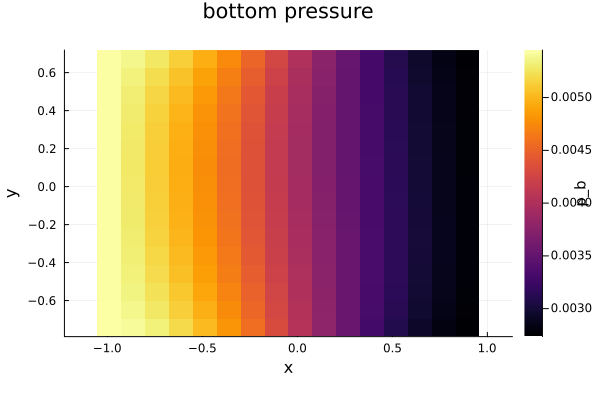

In [9]:
dim_balance_figure = plot_dim_balance(
    dim;
    output=joinpath(@__DIR__, "sample_pg_dim_balance.png"),
)
chi_figure = plot_baroclinic_potential_energy(
    dim;
    output=joinpath(@__DIR__, "sample_pg_chi.png"),
)
bottom_pressure_figure = plot_bottom_pressure(
    dim;
    output=joinpath(@__DIR__, "sample_pg_bottom_pressure.png"),
)
display(dim_balance_figure)
display(chi_figure)
display(bottom_pressure_figure)